# Una epidemia, día a día: el motor corriendo sobre un primer caso

**Pregunta:** En un pueblo de 100000 personas donde hoy hay 50 infectadas y cada infectada contagia en promedio a 2,75 más, ¿cuántas están enfermas en el peor momento, qué día ocurre y qué parte del pueblo ha sido infectada al terminar el brote?

- **Nivel:** 1, Fundamentos
- **Requisitos:** ninguno, este es el notebook de entrada del conjunto
- **Tiempo de lectura:** unos 20 minutos

## Objetivos

Al terminar este notebook puedes correr el motor del pipeline sobre un caso del ejemplo, leer las tres curvas que devuelve y los tres números que las resumen, y decir qué les pasa a esos números cuando cambia una entrada. Es la entrada del conjunto: el notebook siguiente pregunta hasta dónde se puede confiar en la aritmética del propio motor, y el segundo tema explica por qué algunos brotes despegan y otros nunca lo hacen.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Este producto de ejemplo no publica ningún paquete propio: su método vive en `data-pipeline/pipeline/`, así que el notebook importa ese código por su ruta. Un producto importa su propio paquete de PyPI en su lugar (`pip install <paquete>==<versión>`).

La celda siguiente importa las herramientas y los módulos del pipeline, imprime las versiones y define el lector de los parámetros de los casos.

In [1]:
# las herramientas, sus versiones, los módulos del pipeline y el lector de los parámetros de los casos
import importlib.metadata as md
import json
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.io.schema import SIRParams
from pipeline.model.sir import simulate

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def params_of(case_id):
    manifest = ROOT / "data" / "derived" / "manifests" / f"{case_id}.json"
    return SIRParams(case_id, **json.loads(manifest.read_text(encoding="utf-8"))["params"])


index = json.loads((ROOT / "data" / "derived" / "manifests" / "index.json").read_text(encoding="utf-8"))
CASES = [c["case_id"] for c in index["cases"]]

numpy 2.4.6
matplotlib 3.11.2


## Datos

Los parámetros de los cinco casos del ejemplo.

- Propietario: este repositorio (el ejemplo de la plantilla de producto), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Clase de licencia: datos sintéticos que el pipeline produce a partir de los parámetros de cada manifiesto (`real_or_synthetic` es `synthetic`); no hay un conjunto de datos de terceros, así que no aplica ninguna licencia de datos, y la licencia MIT del repositorio cubre los artefactos.
- Archivos leídos: `data/derived/manifests/index.json` y `data/derived/manifests/<caso>.json`, solo por sus parámetros; cada curva que se muestra aquí la calcula el motor.

In [2]:
# los cinco casos: contacto, recuperación, población, primeros infectados, horizonte y R0 = beta / gamma
print(f"{'caso':18s} {'beta':>5s} {'gamma':>6s} {'N':>7s} {'I0':>4s} {'days':>5s} {'R0':>5s}")
for case_id in CASES:
    p = params_of(case_id)
    print(f"{case_id:18s} {p.beta:5.2f} {p.gamma:6.2f} {p.N:7.0f} {p.I0:4.0f} {p.days:5d} {p.beta / p.gamma:5.2f}")
# Relacionar los insumos con sus límites de lectura, sin regenerar documentos.
manifest = json.loads((ROOT / "data/derived/manifests/EX02_epidemic.json").read_text(encoding="utf-8"))
trace = json.loads((ROOT / "data/derived/EX02_epidemic/trace.json").read_text(encoding="utf-8"))
readiness = json.loads((ROOT / "data/derived/readiness.json").read_text(encoding="utf-8"))
api = json.loads((ROOT / "docs/contracts/api.openapi.json").read_text(encoding="utf-8"))
print("schema:", index["schema"], manifest["schema"], trace["schema"])
print("default_case:", index["default_case"], "puntos de traza:", len(trace["t"]))
print("artifact:", manifest["artifact"]["path"], "models:", manifest["models"])
print("readiness:", [(row["id"], row["state"]) for row in readiness["contracts"]])
print("GET:", sorted(api["paths"]))


caso                beta  gamma       N   I0  days    R0
CTRL_degenerate     0.40   0.20  100000    0   160  2.00
EX01_subcritical    0.18   0.25  100000   50   160  0.72
EX02_epidemic       0.55   0.20  100000   50   160  2.75
EX03_fast_burn      1.20   0.20  100000  100   160  6.00
EX04_slow_spread    0.30   0.25  100000   50   160  1.20
schema: example.index/v2 example.manifest/v4 example.trace/v1
default_case: EX02_epidemic puntos de traza: 200
artifact: EX02_epidemic/trace.json models: {'surrogate-model': 'real'}
readiness: [('params-record', 'partial'), ('case-index', 'available'), ('case-manifest', 'available'), ('trace', 'available'), ('surrogate-model', 'available'), ('api', 'missing')]
GET: ['/api/artifacts/{rel_path}', '/api/cases', '/api/cases/{case_id}/manifest', '/api/readiness', '/health', '/healthz']


La tabla de parámetros alimenta el modelo; no contiene contagios observados. Antes de generar una trayectoria, conviene comparar las tasas de contacto y recuperación de los cinco casos declarados. Sus unidades son días inversos, mientras que población e infecciones iniciales se expresan en personas. Leer el índice permite resolver identificadores y categorías bilingües; `default_case` elige el ejemplo inicial, no un caso estadísticamente representativo. El manifiesto relaciona esos insumos con una versión del motor y una ruta de resultado. La traza compacta contiene arreglos `t`, `S`, `I`, `R` y un resumen, en lugar de constituir otra fuente de parámetros.

Las filas de disponibilidad separan procedencia y disponibilidad de calidad numérica. Un manifiesto válido todavía puede describir una generación antigua o un predictor de respaldo; `models["surrogate-model"]` identifica cuál respondió. El documento OpenAPI declara respuestas GET y cuerpos para estados no disponibles. Este ejemplo estático lee archivos versionados directamente: encontrar una ruta en ese documento no significa que exista un servidor activo. Aquí aparecen los límites case-index, case-manifest, trace, readiness y API de un mismo cálculo.

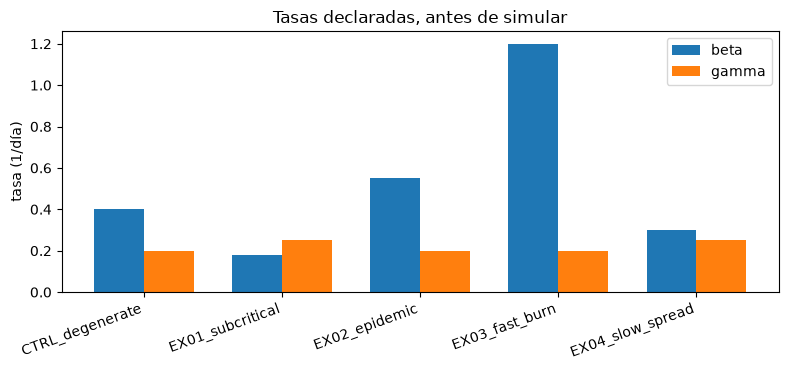

In [3]:
# Comparar los insumos antes de interpretar sus trayectorias generadas.
parameters = [params_of(case_id) for case_id in CASES]
positions = np.arange(len(parameters))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(positions - 0.18, [q.beta for q in parameters], 0.36, label="beta")
ax.bar(positions + 0.18, [q.gamma for q in parameters], 0.36, label="gamma")
ax.set_xticks(positions, CASES, rotation=20, ha="right")
ax.set_ylabel("tasa (1/día)")
ax.set_title("Tasas declaradas, antes de simular")
ax.legend()
fig.tight_layout()
plt.show()

Las barras muestran que los insumos epidémico y rápido comparten recuperación, pero difieren en contacto. El control también tiene una tasa de contacto positiva; su ausencia de infecciones proviene del estado inicial, omitido deliberadamente en esta vista de tasas. Son parámetros de escenarios construidos bajo la licencia MIT del repositorio, no estimaciones ajustadas ni mediciones con incertidumbre muestral. Compararlos aclara qué permanece fijo cuando cambian las curvas posteriores, aunque por sí solos no determinan el pico ni cuándo ocurre.

## Método

El ejemplo modela una epidemia en una población cerrada de $N$ personas con el sistema SIR de Kermack y McKendrick (1927), el modelo de texto que Hethcote (2000) resume. Cada persona está en uno de tres compartimentos: susceptible ($S$), infectada ($I$) o recuperada ($R$). Las personas susceptibles se infectan al encontrarse con infectadas, y las infectadas se recuperan:

$$\frac{dS}{dt} = -\beta \frac{S I}{N}, \qquad \frac{dI}{dt} = \beta \frac{S I}{N} - \gamma I, \qquad \frac{dR}{dt} = \gamma I$$

La tasa de contacto $\beta$ (por día) es a cuántas personas llega una persona infectada en un día, y la tasa de recuperación $\gamma$ (por día) es el inverso de los días que una persona sigue siendo infecciosa. El motor es la función `simulate` de `data-pipeline/pipeline/model/sir.py`. Parte de $I_0$ personas infectadas y todas las demás susceptibles, y avanza estas ecuaciones un cuarto de día a la vez. Tres números resumen una corrida: el pico de $I$, el día de ese pico, y la fracción removida, la parte recuperada R(T)/N al final del horizonte; la fracción que se infectó alguna vez es [I(T)+R(T)]/N.

El campo heredado `attack_rate` devuelve R(T)/N: recuperados o removidos al terminar el horizonte. No incluye a quienes siguen infectados. La fracción que se ha infectado alguna vez hasta T es [I(T)+R(T)]/N; ambas cantidades coinciden solamente si I(T) es despreciable.

Hay cinco casos archivados. La pregunta del notebook trata del tercero, `EX02_epidemic`, con $\beta = 0{,}55$ y $\gamma = 0{,}20$ por día, de modo que una persona infectada contagia a $\beta / \gamma = 2{,}75$ más durante el tiempo que está enferma. La celda siguiente le pide al motor esa corrida y mira lo que devuelve, antes de dibujar nada: cuántos puntos, y los primeros valores de los tres compartimentos. Hay que fijarse en dos cosas: $S$ parte de $N - I_0$, y $I$ empieza a crecer desde el primer paso.

In [4]:
# corre el motor sobre el caso epidémico y mira lo que devuelve
p = params_of("EX02_epidemic")
result = simulate(p)
print(f"puntos: {len(result.t)}, del día {result.t[0]:.2f} al día {result.t[-1]:.2f}")
print("S", [round(v) for v in result.S[:4]])
print("I", [round(v, 1) for v in result.I[:4]])
print("R", [round(v, 1) for v in result.R[:4]])

puntos: 641, del día 0.00 al día 160.00
S [99950, 99943, 99936, 99928]
I [50.0, 54.4, 59.1, 64.3]
R [0.0, 2.5, 5.2, 8.2]


El motor devolvió 641 puntos, uno cada cuarto de día a lo largo de los 160 días del horizonte. En los primeros pasos los infectados suben cerca de un 9 por ciento por paso, de 50 a 54,4 y a 59,1, mientras los recuperados parten de cero y los susceptibles pierden a quienes se infectaron. La celda siguiente dibuja las tres curvas en una figura y marca con una línea punteada el día del pico de infectados.

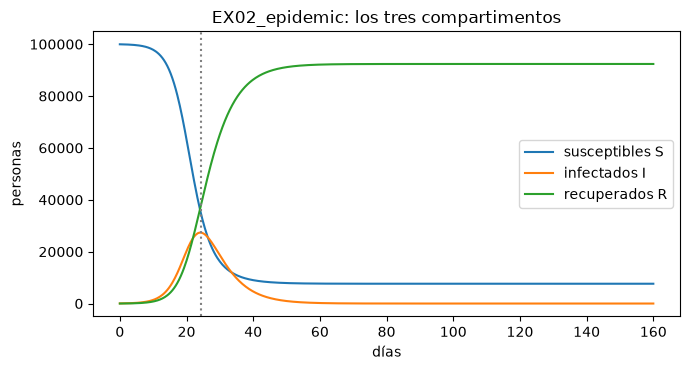

In [5]:
# dibuja los tres compartimentos en el horizonte, con el día del pico de infectados
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(result.t, result.S, label="susceptibles S")
ax.plot(result.t, result.I, label="infectados I")
ax.plot(result.t, result.R, label="recuperados R")
ax.axvline(result.t_peak, color="grey", linestyle=":")
ax.set_xlabel("días")
ax.set_ylabel("personas")
ax.set_title("EX02_epidemic: los tres compartimentos")
ax.legend()
fig.tight_layout()
plt.show()

La figura tiene la forma clásica de una epidemia. La curva de susceptibles cae desde casi todo el pueblo hasta un pequeño remanente, la de recuperados sube como su imagen en el espejo, y la de infectados es una sola joroba que alcanza su máximo en la línea punteada, unas tres semanas y media después del inicio, y luego vuelve hacia cero durante el segundo mes. Lo que la figura no muestra es incertidumbre alguna: es una corrida determinista, sin azar ni barra de error, de modo que la joroba es exacta solo hasta la aritmética del motor, que el notebook siguiente mide.

El motor también entrega por sí mismo los tres números de resumen, así que no hace falta buscarlos en las curvas. La celda los imprime y luego suma los tres compartimentos en cada paso. Un modelo epidémico que crea o pierde personas tiene un error, así que la suma debe mantenerse en la población de 100000.

In [6]:
# Distinguir la fracción removida heredada de todos los infectados hasta el corte.
print(f"pico {result.peak_I:.0f} personas, día {result.t_peak:.2f}")
print(f"removidos R(T)/N {result.attack_rate:.7f}")
ever_infected = (result.I[-1] + result.R[-1]) / p.N
print(f"alguna vez infectados [I(T)+R(T)]/N {ever_infected:.7f}")
total = np.array(result.S) + np.array(result.I) + np.array(result.R)
print(f"S + I + R: {total.min():.1f} .. {total.max():.1f}; N={p.N:.0f}")

pico 27345 personas, día 24.25
removidos R(T)/N 0.9236543
alguna vez infectados [I(T)+R(T)]/N 0.9236543
S + I + R: 100000.0 .. 100000.0; N=100000


Un caso dice poco del modelo. La celda siguiente corre el motor sobre cada caso archivado, incluido el control que parte sin nadie infectado, e imprime los mismos tres números para cada uno, más cuántas veces los infectados iniciales alcanza el pico. Hay que fijarse en cómo se mueven los números con $\beta$ y $\gamma$, y en lo que hace el control.

In [7]:
# el motor sobre cada caso, una línea cada uno, y el pico como múltiplo de los primeros infectados
results = {}
for case_id in CASES:
    q = params_of(case_id)
    results[case_id] = simulate(q)
    r = results[case_id]
    print(f"{case_id:18s} pico {r.peak_I:7.0f}  día {r.t_peak:6.2f}  removidos {r.attack_rate:.4f}", end="  ")
    print(f"x{r.peak_I / max(q.I0, 1):6.1f}")

CTRL_degenerate    pico       0  día   0.00  removidos 0.0000  x   0.0
EX01_subcritical   pico      50  día   0.00  removidos 0.0018  x   1.0
EX02_epidemic      pico   27345  día  24.25  removidos 0.9237  x 546.9
EX03_fast_burn     pico   55265  día   9.25  removidos 0.9982  x 552.7
EX04_slow_spread   pico    1521  día  96.25  removidos 0.2993  x  30.4


La celda siguiente dibuja las curvas de infectados de los cinco casos, cada una como parte de su propia población, para poder comparar sus formas.

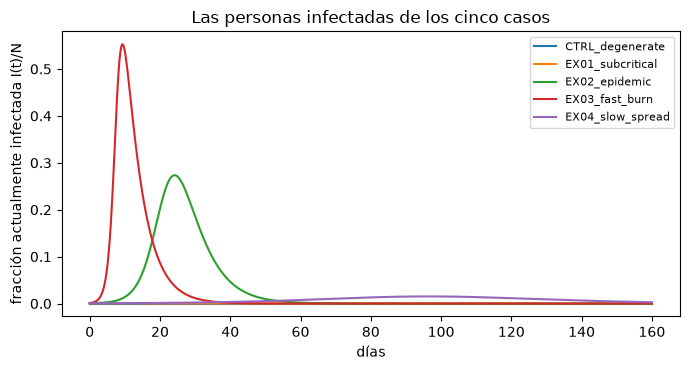

In [8]:
# dibuja las curvas de infectados como parte de cada población, para comparar sus formas
fig, ax = plt.subplots(figsize=(7, 3.8))
for case_id, r in results.items():
    ax.plot(r.t, np.array(r.I) / params_of(case_id).N, label=case_id)
ax.set_xlabel("días")
ax.set_ylabel("fracción actualmente infectada I(t)/N")
ax.set_title("Las personas infectadas de los cinco casos")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Las cinco trayectorias difieren pese a compartir la escala poblacional. La combustión rápida alcanza su máximo temprano y alto, algo más de la mitad del pueblo enfermo a la vez; el caso epidémico lo alcanza unas dos semanas después y a la mitad de esa altura; la propagación lenta es una joroba baja y ancha cerca del día 96 que todavía está bajando cuando acaba el horizonte. El caso subcrítico nunca sube de sus 50 personas iniciales, y el control se queda en el suelo, de modo que un modelo corrido sin nadie infectado correctamente no hace nada. La figura todavía no dice por qué un caso es rápido y otro lento: el segundo tema lo responde con $R_0$.

Ahora una entrada a la vez sobre el caso epidémico. Primero los infectados del día 0: 50, y luego diez y cien veces más. Si el resultado final lo fija la enfermedad y no el fósforo que la encendió, la fracción removida casi no debería moverse, mientras que el momento sí.

In [9]:
# multiplica por 10 y por 100 los primeros infectados, con todo lo demás como en el caso epidémico
for factor in (1, 10, 100):
    q = replace(p, I0=p.I0 * factor)
    r = simulate(q)
    print(f"I0 = {q.I0:5.0f}  pico {r.peak_I:7.0f}  el día {r.t_peak:6.2f}  fracción removida {r.attack_rate:.4f}")

I0 =    50  pico   27345  el día  24.25  fracción removida 0.9237
I0 =   500  pico   27517  el día  17.25  fracción removida 0.9241
I0 =  5000  pico   29235  el día  10.00  fracción removida 0.9287


Segundo, cuánto tiempo sigue infecciosa una persona. El caso epidémico tiene $\gamma = 0{,}20$, un periodo infeccioso de cinco días. Reducir $\gamma$ a la mitad lo lleva a diez días con la misma tasa de contacto, de modo que cada infectada se encuentra con personas susceptibles el doble de tiempo. La celda imprime el cociente $\beta / \gamma$ junto a los tres números, porque es la cantidad sobre la que se construye el segundo tema.

In [10]:
# cambia el periodo infeccioso a 5 y a 10 días, lo que cambia gamma y con él beta / gamma
for infectious_days in (5, 10):
    q = replace(p, gamma=1 / infectious_days)
    r = simulate(q)
    print(f"periodo infeccioso {infectious_days:2d} días  beta/gamma = {q.beta / q.gamma:4.2f}", end="  ")
    print(f"pico {r.peak_I:7.0f}  el día {r.t_peak:6.2f}  fracción removida {r.attack_rate:.4f}")

periodo infeccioso  5 días  beta/gamma = 2.75  pico   27345  el día  24.25  fracción removida 0.9237
periodo infeccioso 10 días  beta/gamma = 5.50  pico   51617  el día  21.25  fracción removida 0.9963


## Resultados

**Respuesta:** En el caso epidémico el peor momento son 27345 personas enfermas a la vez, el día 24,25, y al final de los 160 días ha sido infectada una fracción de 0,9237 del pueblo, casi el 92,4 por ciento. Partir con 500 o con 5000 infectados en lugar de 50 adelanta el pico, al día 17,25 y al día 10,00, y sube la fracción removida solo de 0,9237 a 0,9241 y a 0,9287, de modo que el fósforo que enciende el brote fija su momento y casi no su tamaño. Un periodo infeccioso de diez días en lugar de cinco duplica $\beta / \gamma$ hasta 5,50, lleva el pico a 51617 personas y la fracción removida a 0,9963: el tamaño sí depende del cociente.

Los números describen una población cerrada y homogénea, sin vacunación, sin distanciamiento y sin azar, así que son lo que implican las ecuaciones y no un pronóstico de un pueblo real. Además arrastran el error aritmético del propio motor, unas pocas milésimas en la fracción removida, que el notebook siguiente cuantifica. La figura de los cinco casos muestra que la forma del brote cambia mucho con $\beta$ y $\gamma$, pero todavía no dice qué combinación decide si hay brote.

En este caso epidémico I(T) es prácticamente cero, por lo que 0,9237 representa ambas fracciones al redondear. No ocurre en toda la familia: el caso lento conserva infectados al día 160. Sus curvas y su campo `attack_rate` no bastan para confundir removidos con todos los infectados hasta el corte.

## Resumen

- Una llamada a `simulate` devuelve todo el curso de un brote: tres curvas y, derivados de ellas, un pico, el día del pico y una fracción removida.
- El caso epidémico alcanza su máximo de 27345 infectados el día 24,25 y termina con 0,9237 del pueblo infectado.
- Más infectados iniciales adelantan el pico y dejan el tamaño final casi igual.
- Un periodo infeccioso más largo sube el pico y el tamaño final, a través de $\beta / \gamma$.
- Siguiente: qué tan exacta es la aritmética de cuarto de día del motor, en el notebook 02 de este tema.

## Referencias

- Kermack, W. O. y McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- Hethcote, H. W. (2000). The mathematics of infectious diseases. SIAM Review. https://doi.org/10.1137/S0036144500371907
- NumPy, https://pypi.org/project/numpy/ (fijado en `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (fijado en `notebooks/requirements.txt`).
- El motor y los casos de este repositorio, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`).